--- 5 dòng đầu tiên ---
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

--- Kiểu dữ liệu ---
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age  

C:\Users\Chau\AppData\Local\Temp\ipykernel_17656\1012291915.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=diabetes_data, x="Outcome", palette="Set2")


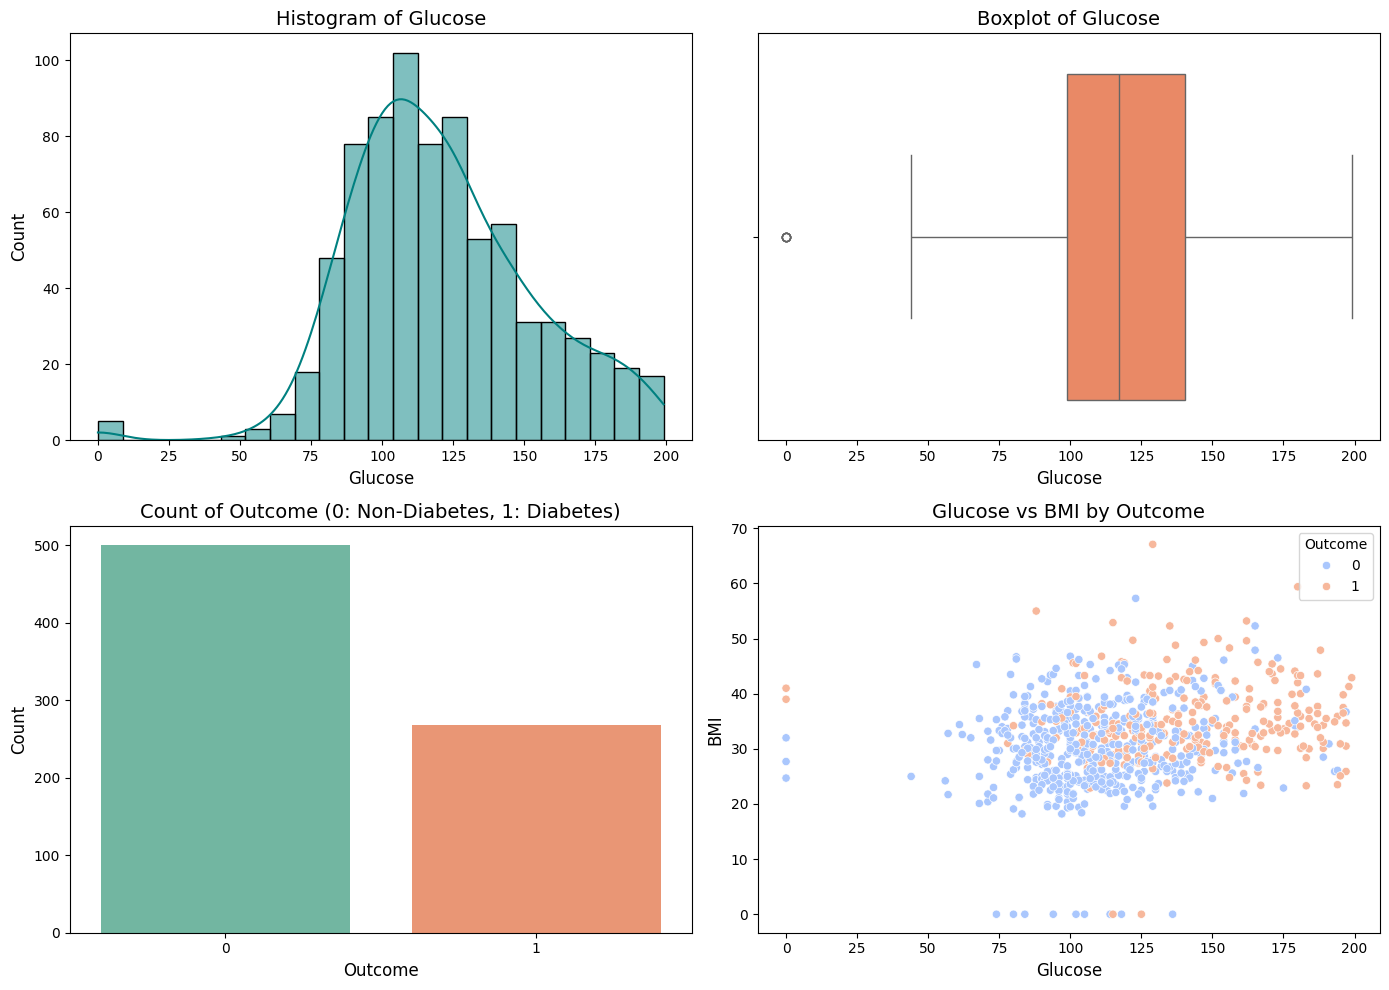

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns

# 1. Nạp tập dữ liệu tiểu đường vào DataFrame (thay đổi tên file .csv cho khớp với file bạn đã tải)
diabetes_data = pd.read_csv("diabetes.csv")

# Kiểm tra sơ bộ dữ liệu
print("--- 5 dòng đầu tiên ---")
print(diabetes_data.head(5))
print("\n--- Kiểu dữ liệu ---")
print(diabetes_data.dtypes)
print("\n--- Kích thước dữ liệu ---")
print(diabetes_data.shape)

# Chọn cột muốn phân tích thống kê (ví dụ: 'Glucose' hoặc 'BMI')
target_col = "Glucose"

# 2. Tính toán các chỉ số thống kê mô tả sử dụng numpy và scipy
data_mean = np.mean(diabetes_data[target_col])
data_median = np.median(diabetes_data[target_col])
data_mode = stats.mode(diabetes_data[target_col], keepdims=True)
data_variance = np.var(diabetes_data[target_col])
data_sd = np.std(diabetes_data[target_col])
data_max = np.max(diabetes_data[target_col])
data_min = np.min(diabetes_data[target_col])
data_percentile = np.percentile(diabetes_data[target_col], 60)
data_quartile = np.quantile(diabetes_data[target_col], 0.75)
data_IQR = stats.iqr(diabetes_data[target_col])

print(f"\n--- Thống kê mô tả cho cột '{target_col}' ---")
print(f"Mean (Trung bình): {data_mean:.2f}")
print(f"Median (Trung vị): {data_median:.2f}")
print(f"Mode (Mốt): {data_mode.mode[0]}")
print(f"Variance (Phương sai): {data_variance:.2f}")
print(f"Standard Deviation (Độ lệch chuẩn): {data_sd:.2f}")
print(f"Min: {data_min} | Max: {data_max}")
print(f"60th Percentile: {data_percentile:.2f}")
print(f"0.75 Quantile (Q3): {data_quartile:.2f}")
print(f"IQR (Khoảng tứ phân vị): {data_IQR:.2f}")

# 3. Trực quan hóa dữ liệu (Vẽ biểu đồ)
plt.figure(figsize=(14, 10))

# Biểu đồ 1: Histogram phân bố chỉ số Glucose
plt.subplot(2, 2, 1)
sns.histplot(data=diabetes_data, x=target_col, kde=True, color="teal")
plt.title(f"Histogram of {target_col}", fontsize=14)
plt.xlabel(target_col, fontsize=12)
plt.ylabel("Count", fontsize=12)

# Biểu đồ 2: Boxplot kiểm tra giá trị ngoại lai (Outliers)
plt.subplot(2, 2, 2)
sns.boxplot(data=diabetes_data, x=target_col, color="coral")
plt.title(f"Boxplot of {target_col}", fontsize=14)
plt.xlabel(target_col, fontsize=12)

# Biểu đồ 3: Countplot đếm số người không mắc (0) và mắc bệnh (1)
plt.subplot(2, 2, 3)
sns.countplot(data=diabetes_data, x="Outcome", palette="Set2")
plt.title("Count of Outcome (0: Non-Diabetes, 1: Diabetes)", fontsize=14)
plt.xlabel("Outcome", fontsize=12)
plt.ylabel("Count", fontsize=12)

# Biểu đồ 4: Scatter plot mối quan hệ giữa Glucose và BMI phân loại theo Outcome
plt.subplot(2, 2, 4)
sns.scatterplot(
    data=diabetes_data, x="Glucose", y="BMI", hue="Outcome", palette="coolwarm"
)
plt.title("Glucose vs BMI by Outcome", fontsize=14)
plt.xlabel("Glucose", fontsize=12)
plt.ylabel("BMI", fontsize=12)

plt.tight_layout()
plt.show()